## Explore data 

In [27]:
import pandas as pd

raw = pd.read_csv("titanic-dataset.csv")
df = raw.copy()

print(df.shape, "\n")

(891, 12) 



In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [29]:
print(df.isna().sum().sort_values(ascending=False), "\n")

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64 



In [30]:
print(df.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [31]:
print(df["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [32]:
for col in ["Sex", "Pclass", "Embarked", "SibSp", "Parch"]:
    print(df.groupby(col)["Survived"].agg(["mean", "count", "sum"]), "\n")

            mean  count  sum
Sex                         
female  0.742038    314  233
male    0.188908    577  109 

            mean  count  sum
Pclass                      
1       0.629630    216  136
2       0.472826    184   87
3       0.242363    491  119 

              mean  count  sum
Embarked                      
C         0.553571    168   93
Q         0.389610     77   30
S         0.336957    644  217 

           mean  count  sum
SibSp                      
0      0.345395    608  210
1      0.535885    209  112
2      0.464286     28   13
3      0.250000     16    4
4      0.166667     18    3
5      0.000000      5    0
8      0.000000      7    0 

           mean  count  sum
Parch                      
0      0.343658    678  233
1      0.550847    118   65
2      0.500000     80   40
3      0.600000      5    3
4      0.000000      4    0
5      0.200000      5    1
6      0.000000      1    0 



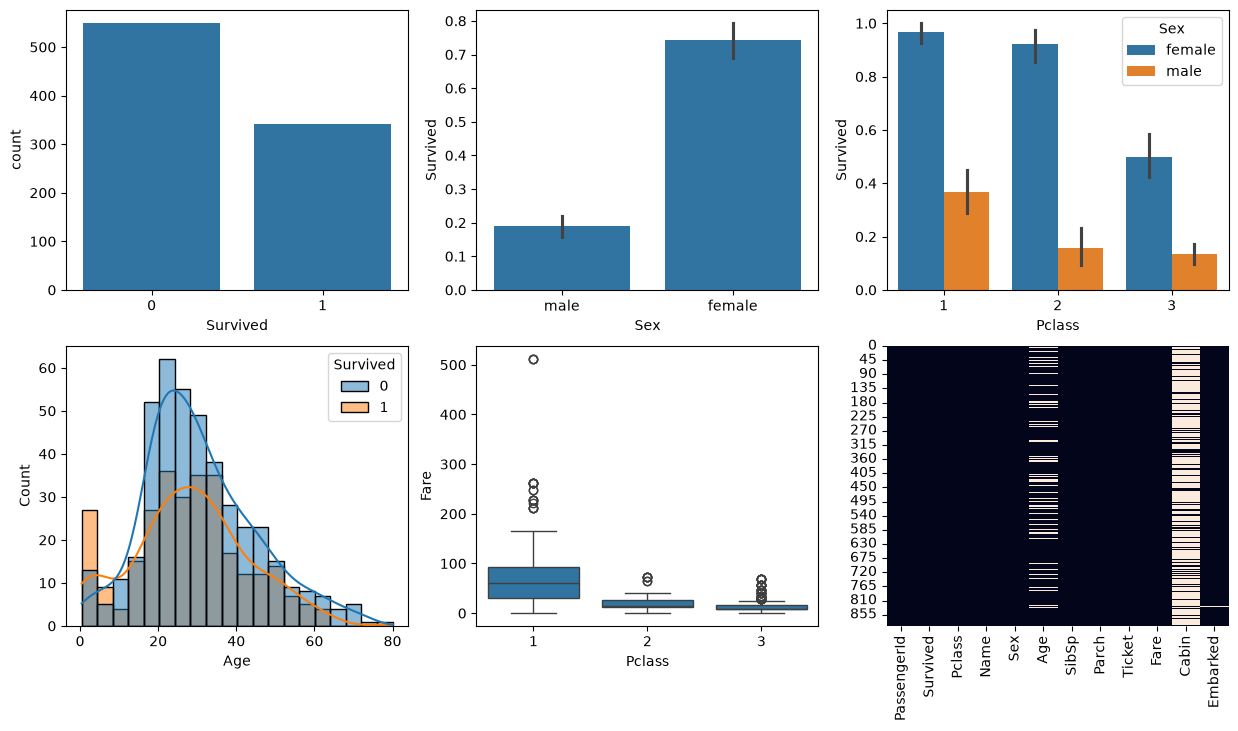

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(data=df, x="Survived", ax=axes[0, 0])
sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0, 1])
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", ax=axes[0, 2])
sns.histplot(data=df, x="Age", hue="Survived", kde=True, ax=axes[1, 0])
sns.boxplot(data=df, x="Pclass", y="Fare", ax=axes[1, 1])
sns.heatmap(df.isna(), cbar=False, ax=axes[1, 2])

plt.show()

In [34]:
print(df.duplicated().sum())
print(df["Fare"].describe(percentiles=[0.5, 0.9, 0.99]))

0
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
50%       14.454200
90%       77.958300
99%      249.006220
max      512.329200
Name: Fare, dtype: float64


In [35]:
print(df.shape)
print(df["Cabin"].isna().sum() / df.shape[0])

# Most of the Cabin values are NA's. I'll remove the Cabin column
df = df.drop(columns=["Cabin", "PassengerId"])

(891, 12)
0.7710437710437711


## Transform data

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

X = df[numeric_features + categorical_features]
y = df["Survived"]

numeric_pipe = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="mean")),
    ]
)

categorical_pipe = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ]
)

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score, train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

logreg = Pipeline(
    [("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))]
)

forest = Pipeline(
    [
        ("prep", preprocessor),
        (
            "model",
            RandomForestClassifier(n_estimators=200, random_state=42, max_depth=4),
        ),
    ]
)

for name, pipe in [("logreg", logreg), ("forest", forest)]:
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"{name}: {scores.mean():.3f} (+/- {scores.std():.3f})")

logreg: 0.802 (+/- 0.029)
forest: 0.820 (+/- 0.020)


## Train and assess (forest)

In [38]:
pipeline = forest
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
print("Test accuracy: ", accuracy_score(y_test, y_pred))
print("Pipeline score: ", pipeline.score(X_train, y_train))
print(classification_report(y_test, y_pred))

Test accuracy:  0.8026905829596412
Pipeline score:  0.8458083832335329
              precision    recall  f1-score   support

           0       0.79      0.92      0.85       137
           1       0.83      0.62      0.71        86

    accuracy                           0.80       223
   macro avg       0.81      0.77      0.78       223
weighted avg       0.81      0.80      0.80       223



## Save the model

In [39]:
import joblib

joblib.dump(pipeline, "model.joblib")

['model.joblib']